# Project Evidence Notebook: Student Performance & At-Risk Prediction
**Candidate:** Dasari Nishanth Reddy | **Reg. No.:** 12302189 | **Role:** AI & Machine Learning

This notebook is the evidence for the assessment: data, EDA, leakage checks, chronological split,
baselines vs models, held-out test metrics, error/fairness analysis and a real prediction from the saved model.
It is advisory decision support only. Data is **synthetic** (no real student data). Built with AI assistance (see README).

In [1]:
import sys, json
sys.path.insert(0, "..")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src import config as C
from src.generate_data import generate
from src.features import prepare_X
pd.set_option("display.width", 140)

## 1. Problem definition
At the end of week 8, predict whether a student will score **below 50** on the week-10 assessment (`needs_support = 1`), using only week 1-8 information.

## 2. Data (synthetic, reproducible with seed 42)

In [2]:
df = generate()              # same generator as src/generate_data.py
print(df.shape, "positive rate:", round(df[C.TARGET].mean(), 3))
df.head()

(1800, 13) positive rate: 0.234


,student_id,term,gender,attendance_rate,attendance_recent,assignment_completion,late_submission_rate,lms_hours_per_week,prev_score_1,prev_score_2,prev_score_3,next_score,needs_support
0,T1-0000,1,F,0.769083,0.766701,0.793418,0.237674,7.404622,59.688193,65.885823,63.881411,68.887725,0
1,T1-0001,1,M,0.709945,0.703912,0.770475,0.282440,6.889074,36.636002,53.707296,54.377409,45.117507,1
2,T1-0002,1,F,0.952304,0.934038,0.937590,0.244137,5.267441,74.039230,71.036522,62.754779,85.525832,0
3,T1-0003,1,F,0.817191,0.792612,0.722824,0.068538,7.286886,87.186777,79.201548,72.455631,76.703817,0
4,T1-0004,1,F,0.656867,0.612010,0.550873,0.245420,2.417342,50.265535,36.297119,40.176612,6.391481,1


## 3. Data-quality checks

In [3]:
print("Missing % per feature:")
print((df[C.FEATURES].isna().mean()*100).round(2))
print("LMS hours > 30 (outliers):", (df.lms_hours_per_week > 30).sum())
print("Duplicate student ids:", df.student_id.duplicated().sum())

Missing % per feature:
attendance_rate          0.00
attendance_recent        2.94
assignment_completion    0.00
late_submission_rate     0.00
lms_hours_per_week       4.44
prev_score_1             4.61
prev_score_2             0.00
prev_score_3             0.00
dtype: float64
LMS hours > 30 (outliers): 9
Duplicate student ids: 0


## 4. EDA

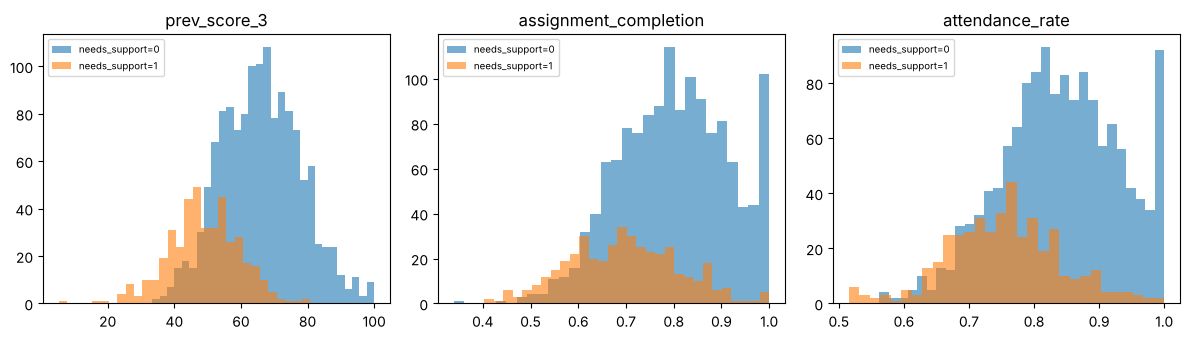

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col in zip(axes, ["prev_score_3", "assignment_completion", "attendance_rate"]):
    for lab, g in df.groupby(C.TARGET):
        ax.hist(g[col].dropna(), bins=30, alpha=.6, label=f"needs_support={lab}")
    ax.set_title(col); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 5. Leakage and sensitive-attribute checks

In [5]:
print("Future/target columns used as features:", set(C.ALL_FEATURES) & set(C.LEAKY))
print("Sensitive columns used as features:", set(C.ALL_FEATURES) & set(C.SENSITIVE))
corr = prepare_X(df).corrwith(df[C.TARGET].astype(float)).abs().sort_values(ascending=False)
print("\nAbsolute correlation of each feature with the target:")
print(corr.round(3))

Future/target columns used as features: set()
Sensitive columns used as features: set()

Absolute correlation of each feature with the target:
avg_prev_score           0.566
prev_score_3             0.530
prev_score_2             0.507
prev_score_1             0.502
attendance_rate          0.382
attendance_recent        0.381
assignment_completion    0.366
late_submission_rate     0.296
lms_hours_per_week       0.260
attendance_change        0.144
score_trend              0.057
dtype: float64


## 6. Chronological split
Term 1 = train, term 2 = validation (model + threshold choice), term 3 = held-out test (used once).

In [6]:
print(df.groupby("term").size())

term
1    600
2    600
3    600
dtype: int64


## 7. Results from the training pipeline (`python -m src.train`)

In [7]:
m = json.load(open("../reports/metrics.json"))
rows = []
for name, r in m["results"].items():
    t = r["test"]; cm = t["confusion_matrix"]
    rows.append({"model": name, "precision": t["precision"], "recall": t["recall"], "f1": t["f1"],
                 "roc_auc": t["roc_auc"], "TP": cm["tp"], "FP": cm["fp"], "FN": cm["fn"], "TN": cm["tn"]})
pd.DataFrame(rows).set_index("model")

,precision,recall,f1,roc_auc,TP,FP,FN,TN
model,,,,,,,,
baseline_majority_class,0.000,0.000,0.000,0.500,0,0,127,473
baseline_rule_avg_prev_score,0.482,0.866,0.620,0.900,110,118,17,355
logistic_regression,0.445,0.953,0.607,0.928,121,151,6,322
random_forest,0.476,0.953,0.635,0.927,121,133,6,340
hist_gradient_boosting,0.413,0.984,0.581,0.913,125,178,2,295


Selected on validation F2: logistic_regression


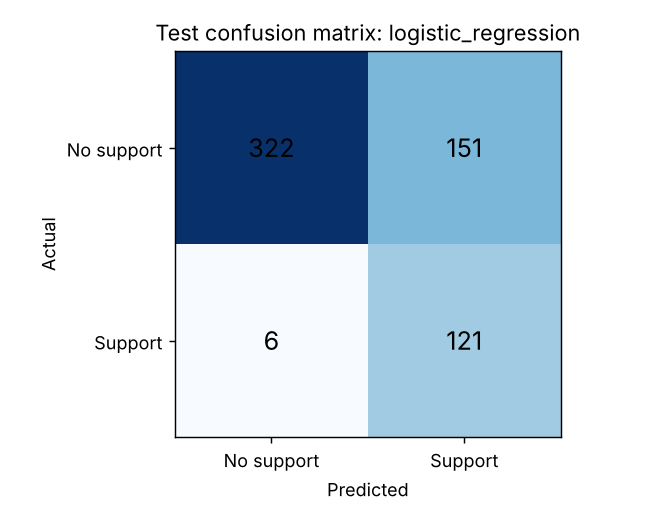

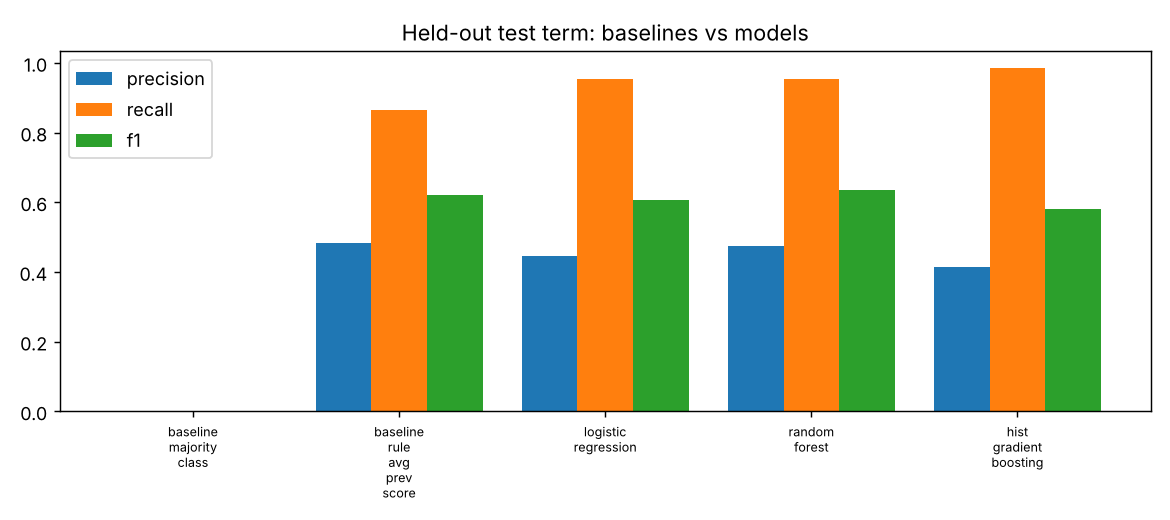

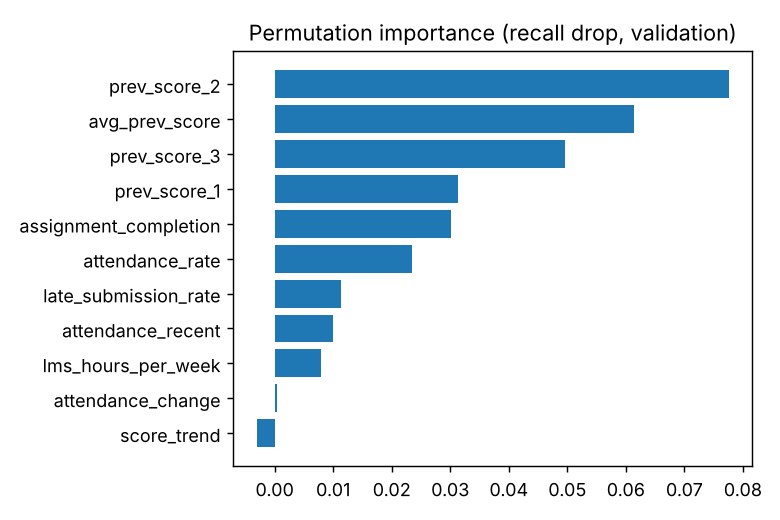

In [8]:
print("Selected on validation F2:", m["selected_model"])
from IPython.display import Image, display
display(Image("../reports/confusion_matrix.png"))
display(Image("../reports/model_comparison.png"))
display(Image("../reports/feature_importance.png"))

## 8. Error analysis and fairness audit (gender used for audit only)

In [9]:
print("Fairness audit (test term):"); print(pd.DataFrame(m["fairness_audit_test"]).T)
print("\nFalse-positive profile:", m["error_analysis_test"]["false_positive_profile_mean"])
print("False-negative profile:", m["error_analysis_test"]["false_negative_profile_mean"])

Fairness audit (test term):
       n  flag_rate  recall  precision
F  298.0      0.453   0.924      0.452
M  302.0      0.454   0.984      0.438

False-positive profile: {'avg_prev_score': 56.0, 'assignment_completion': 0.75, 'attendance_rate': 0.8}
False-negative profile: {'avg_prev_score': 63.36, 'assignment_completion': 0.8, 'attendance_rate': 0.8}


## 9. Real prediction from the saved model artifact

In [10]:
from src.predict import RiskPredictor
p = RiskPredictor()   # loads models/risk_model.joblib
sample = dict(attendance_rate=.6, attendance_recent=.5, assignment_completion=.4,
              late_submission_rate=.4, lms_hours_per_week=2, prev_score_1=45, prev_score_2=40, prev_score_3=38)
print(json.dumps(p.predict(sample), indent=2))

{
  "risk_probability": 0.996,
  "risk_band": "High",
  "flagged_for_support": true,
  "top_signals": [
    {
      "signal": "assignment completion",
      "feature": "assignment_completion",
      "value": 0.4,
      "effect": "raises risk",
      "impact": 0.017
    },
    {
      "signal": "middle previous score",
      "feature": "prev_score_2",
      "value": 40.0,
      "effect": "raises risk",
      "impact": 0.009
    },
    {
      "signal": "average previous score",
      "feature": "avg_prev_score",
      "value": 41.0,
      "effect": "raises risk",
      "impact": 0.007
    }
  ],
  "model": "logistic_regression",
  "uncertainty_notes": [
    "Probability is an estimate from a model trained on synthetic data; treat it as a prompt for a conversation, not a verdict."
  ],
  "human_review_note": "Advisory only. This score must be reviewed by a teacher/counsellor and must never be used for grading, punishment or admission decisions."
}


## 10. Limitations
- Synthetic data: shows the pipeline works, not real-world accuracy; revalidate on real, consented data.
- Precision is below 0.5, so many flagged students will not fall below 50. Use as a prompt for a human conversation.
- Single-feature explanations understate impact when features are correlated or probability is saturated.
- Output must be reviewed by a teacher; never for grading, punishment or admission decisions.